# [4-a] CNN에 Dropout 넣기

[3-b] 결과에서 CNN은 val acc 0.85였지만, train acc가 0.97~0.99까지 올라가서 과적합이 있었어요.
[2-b] MLP에서 Dropout이 효과가 있었으니, CNN의 `fc1` 뒤에도 Dropout을 넣어 비교합니다.

| 버전 | Dropout | lr |
|---|---|---|
| A 기본 (= [3-b] CNN 64) | 없음 | 0.001 |
| B Dropout | 0.5 (fc1 뒤) | 0.001 |

둘 다 Early Stopping (val loss가 5번 연속 안 좋아지면 멈춤)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
# 검증은 A040 선수 (tk_2, tk_3와 똑같이 나눔 → 결과 비교 가능)
VAL_PERSON = "A040"

def make_loaders(img_size):
    transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])
    dataset = datasets.ImageFolder("tk_crops", transform=transform)
    train_idx = [i for i, (p, _) in enumerate(dataset.samples) if VAL_PERSON not in os.path.basename(p)]
    val_idx = [i for i, (p, _) in enumerate(dataset.samples) if VAL_PERSON in os.path.basename(p)]
    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=32, shuffle=True)
    val_loader = DataLoader(Subset(dataset, val_idx), batch_size=32, shuffle=False)
    return dataset.classes, train_loader, val_loader

In [3]:
classes, train_loader, val_loader = make_loaders(64)
print("클래스:", classes, "/ train:", len(train_loader.dataset), " val:", len(val_loader.dataset))

클래스: ['1_start', '2_middle', '3_end'] / train: 933  val: 264


In [4]:
criterion = nn.CrossEntropyLoss()

def train_model(model, optimizer, train_loader, val_loader, save_path, max_epochs=50, patience=5):
    """학습 + Early Stopping
    - val loss가 좋아질 때마다 모델을 파일(save_path)로 저장
    - patience번 연속으로 안 좋아지면 학습을 멈춤
    - 끝나면 제일 좋았던 모델을 다시 불러옴
    """
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss = float("inf")    # 지금까지 제일 낮은 val loss (처음엔 무한대)
    wait = 0                    # 몇 번 연속으로 안 좋아졌는지

    for epoch in range(max_epochs):
        # ----- 학습 -----
        model.train()
        total_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = total_loss / total, correct / total

        # ----- 검증 -----
        model.eval()
        total_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                total_loss += criterion(outputs, labels).item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = total_loss / total, correct / total

        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        msg = f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}"

        # ----- Early Stopping -----
        if val_loss < best_loss:
            best_loss = val_loss
            wait = 0
            torch.save(model.state_dict(), save_path)     # 제일 좋은 모델 저장
            msg += "  ← best 저장"
        else:
            wait += 1
            msg += f"  (좋아지지 않음 {wait}/{patience})"
        print(msg)
        if wait >= patience:
            print(f"→ {patience}번 연속 val loss가 좋아지지 않아서 {epoch + 1} epoch에서 멈춤")
            break

    model.load_state_dict(torch.load(save_path))          # 제일 좋았던 모델로 되돌리기
    return history

In [5]:
def evaluate(model, val_loader, n_classes=3):
    """정확도와 혼동행렬 (행 = 정답, 열 = 예측)"""
    model.eval()
    cm = np.zeros((n_classes, n_classes), dtype=int)
    with torch.no_grad():
        for images, labels in val_loader:
            preds = model(images.to(device)).argmax(1).cpu()
            for t, p in zip(labels, preds):
                cm[t, p] += 1
    acc = np.trace(cm) / cm.sum()       # 대각선 합 / 전체
    return acc, cm

def plot_cm(cm, classes, title):
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(len(classes)), classes); plt.yticks(range(len(classes)), classes)
    plt.xlabel("예측"); plt.ylabel("정답"); plt.title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, cm[i, j], ha="center", va="center")

## CNN (dropout 값만 바꿔서 쓰기)

In [6]:
class CNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.dropout = nn.Dropout(dropout)     # ← 추가된 부분 (0이면 아무것도 안 함)
        self.fc2 = nn.Linear(128, 3)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # (N, 16, 32, 32)
        x = self.pool(self.relu(self.conv2(x)))   # (N, 32, 16, 16)
        x = self.pool(self.relu(self.conv3(x)))   # (N, 64, 8, 8)
        x = x.view(x.size(0), -1)                 # (N, 4096)
        x = self.relu(self.fc1(x))                # (N, 128)
        x = self.dropout(x)                       # 학습 때만 128개 중 절반을 무작위로 0으로
        return self.fc2(x)                        # (N, 3)

print(CNN(0.5))

CNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=3, bias=True)
)


In [7]:
# Dropout이 train / eval 모드에서 어떻게 다른지 직접 확인
d = nn.Dropout(0.5)
x = torch.ones(1, 10)
d.train(); print("train 모드:", d(x))   # 절반은 0, 나머지는 2배 (평균을 맞추려고)
d.eval();  print("eval  모드:", d(x))   # 그대로 통과

train 모드: tensor([[2., 2., 2., 0., 0., 2., 0., 0., 0., 0.]])
eval  모드: tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


## A. 기본

In [8]:
results, models, val_loaders = {}, {}, {}
torch.manual_seed(42)
m = CNN(dropout=0.0).to(device)
results["A 기본"] = train_model(m, optim.Adam(m.parameters(), lr=0.001), train_loader, val_loader, "best_cnn_A.pth")
models["A 기본"], val_loaders["A 기본"] = m, val_loader

Epoch  1 | train loss 1.1004 acc 0.3880 | val loss 1.0733 acc 0.5189  ← best 저장
Epoch  2 | train loss 0.9418 acc 0.5423 | val loss 0.9360 acc 0.5000  ← best 저장
Epoch  3 | train loss 0.7818 acc 0.6356 | val loss 0.7615 acc 0.7197  ← best 저장
Epoch  4 | train loss 0.6440 acc 0.7160 | val loss 0.6370 acc 0.6932  ← best 저장
Epoch  5 | train loss 0.4846 acc 0.8049 | val loss 0.6373 acc 0.6742  (좋아지지 않음 1/5)
Epoch  6 | train loss 0.4279 acc 0.8242 | val loss 0.5698 acc 0.7462  ← best 저장
Epoch  7 | train loss 0.3224 acc 0.8650 | val loss 0.4893 acc 0.7992  ← best 저장
Epoch  8 | train loss 0.2847 acc 0.8907 | val loss 0.4617 acc 0.8295  ← best 저장
Epoch  9 | train loss 0.2052 acc 0.9282 | val loss 0.5394 acc 0.7689  (좋아지지 않음 1/5)
Epoch 10 | train loss 0.1840 acc 0.9250 | val loss 0.4768 acc 0.8333  (좋아지지 않음 2/5)
Epoch 11 | train loss 0.2120 acc 0.9153 | val loss 0.4924 acc 0.8258  (좋아지지 않음 3/5)
Epoch 12 | train loss 0.1375 acc 0.9507 | val loss 0.4630 acc 0.8295  (좋아지지 않음 4/5)
Epoch 13 | train los

## B. Dropout 0.5

In [9]:
torch.manual_seed(42)
m = CNN(dropout=0.5).to(device)
results["B Dropout"] = train_model(m, optim.Adam(m.parameters(), lr=0.001), train_loader, val_loader, "best_cnn_B.pth")
models["B Dropout"], val_loaders["B Dropout"] = m, val_loader

Epoch  1 | train loss 1.1037 acc 0.3655 | val loss 1.0836 acc 0.4621  ← best 저장
Epoch  2 | train loss 0.9945 acc 0.5080 | val loss 0.9304 acc 0.5492  ← best 저장
Epoch  3 | train loss 0.8468 acc 0.5734 | val loss 0.8147 acc 0.6742  ← best 저장
Epoch  4 | train loss 0.7267 acc 0.6592 | val loss 0.7206 acc 0.6856  ← best 저장
Epoch  5 | train loss 0.6324 acc 0.7310 | val loss 0.6133 acc 0.7689  ← best 저장
Epoch  6 | train loss 0.5430 acc 0.7674 | val loss 0.5535 acc 0.7652  ← best 저장
Epoch  7 | train loss 0.4965 acc 0.7931 | val loss 0.4899 acc 0.7955  ← best 저장
Epoch  8 | train loss 0.4130 acc 0.8274 | val loss 0.4703 acc 0.8258  ← best 저장
Epoch  9 | train loss 0.3802 acc 0.8510 | val loss 0.4340 acc 0.8295  ← best 저장
Epoch 10 | train loss 0.3169 acc 0.8757 | val loss 0.4158 acc 0.8674  ← best 저장
Epoch 11 | train loss 0.2938 acc 0.8842 | val loss 0.4363 acc 0.8295  (좋아지지 않음 1/5)
Epoch 12 | train loss 0.2555 acc 0.9035 | val loss 0.4141 acc 0.8598  ← best 저장
Epoch 13 | train loss 0.2470 acc 0.9

## 비교

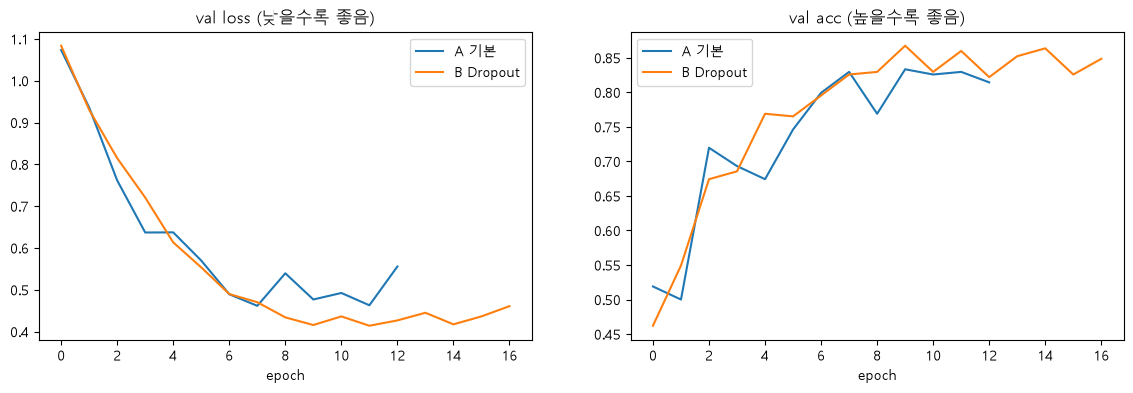

In [10]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for name, h in results.items():
    plt.plot(h["val_loss"], label=name)
plt.title("val loss (낮을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
for name, h in results.items():
    plt.plot(h["val_acc"], label=name)
plt.title("val acc (높을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.show()

버전                 | 멈춘 epoch | best epoch | train acc | val acc | 차이(과적합)
A 기본               |         13 |          8 | 0.8907    | 0.8295  | +0.0611
B Dropout          |         17 |         12 | 0.9035    | 0.8598  | +0.0437


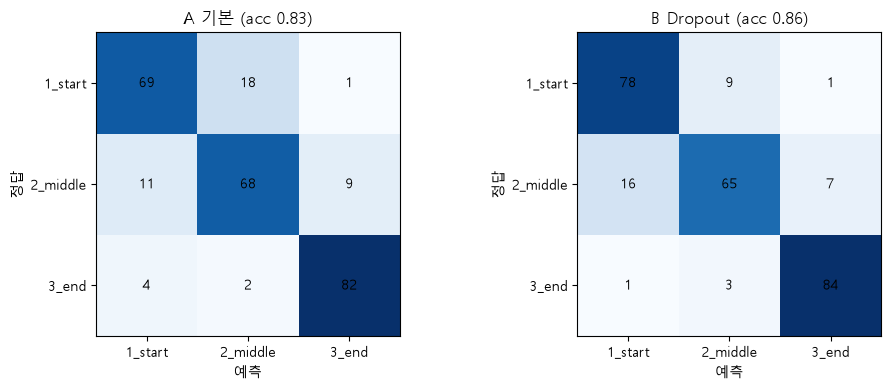

In [11]:
# 버전별 결과 정리 (best 저장 시점 = val loss가 제일 낮았던 epoch)
print(f"{'버전':18s} | 멈춘 epoch | best epoch | train acc | val acc | 차이(과적합)")
plt.figure(figsize=(5 * len(models), 4))
for k, (name, m) in enumerate(models.items()):
    h = results[name]
    best = int(np.argmin(h["val_loss"]))
    acc, cm = evaluate(m, val_loaders[name])
    gap = h["train_acc"][best] - acc
    print(f"{name:18s} | {len(h['val_loss']):10d} | {best + 1:10d} | {h['train_acc'][best]:.4f}    | {acc:.4f}  | {gap:+.4f}")
    plt.subplot(1, len(models), k + 1)
    plot_cm(cm, classes, f"{name} (acc {acc:.2f})")
plt.tight_layout(); plt.show()

## 생각해볼 것
1. "차이(과적합)" 값이 Dropout을 넣고 줄었어?
2. Dropout을 넣으면 학습이 느려지는 대신 오래 학습해(epoch 수 비교). 왜 그럴까?
3. Dropout을 `fc1` 뒤에만 넣었는데, conv 층 뒤에도 넣으면 어떨까? (`nn.Dropout2d`)